In [1]:
!nvidia-smi
!pip install -q ultralytics roboflow

Tue Oct 13 12:55:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="2oeRaawmVxEws14a9xm6")
project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
version = project.version(20)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-players-detection-20 in yolov8:: 100%|██████████| 756/756 [00:00<00:00, 8735.41it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
print(dataset.location)
!ls {dataset.location}
!cat {dataset.location}/data.yaml

/content/football-players-detection-20
data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid
names:
- ball
- goalkeeper
- player
- referee
nc: 4
roboflow:
  license: CC BY 4.0
  project: football-players-detection-3zvbc
  url: https://universe.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc/dataset/20
  version: 20
  workspace: roboflow-jvuqo
test: ../test/images
train: ../train/images
val: ../valid/images


In [5]:
import os, yaml

p = f"{dataset.location}/data.yaml"
with open(p) as f:
    d = yaml.safe_load(f)

d["path"] = dataset.location
d["train"] = "train/images"
d["val"] = "valid/images"
if os.path.exists(f"{dataset.location}/test/images"):
    d["test"] = "test/images"
else:
    d.pop("test", None)

with open(p, "w") as f:
    yaml.dump(d, f)

!cat {p}

names:
- ball
- goalkeeper
- player
- referee
nc: 4
path: /content/football-players-detection-20
roboflow:
  license: CC BY 4.0
  project: football-players-detection-3zvbc
  url: https://universe.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc/dataset/20
  version: 20
  workspace: roboflow-jvuqo
test: test/images
train: train/images
val: valid/images


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")
model.train(
    data="/content/football-players-detection-20/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project="/content/drive/MyDrive/football",
    name="run1",
)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/football-players-detection-20/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=run1, nbs=64, nms=None, opset=None, optim

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7adbf54c9e10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [8]:
  YOLO("/content/drive/MyDrive/football/run1/weights/last.pt").train(resume=True)

WARNING ⚠️ model '/content/drive/MyDrive/football/run1/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_wi

KeyboardInterrupt: 

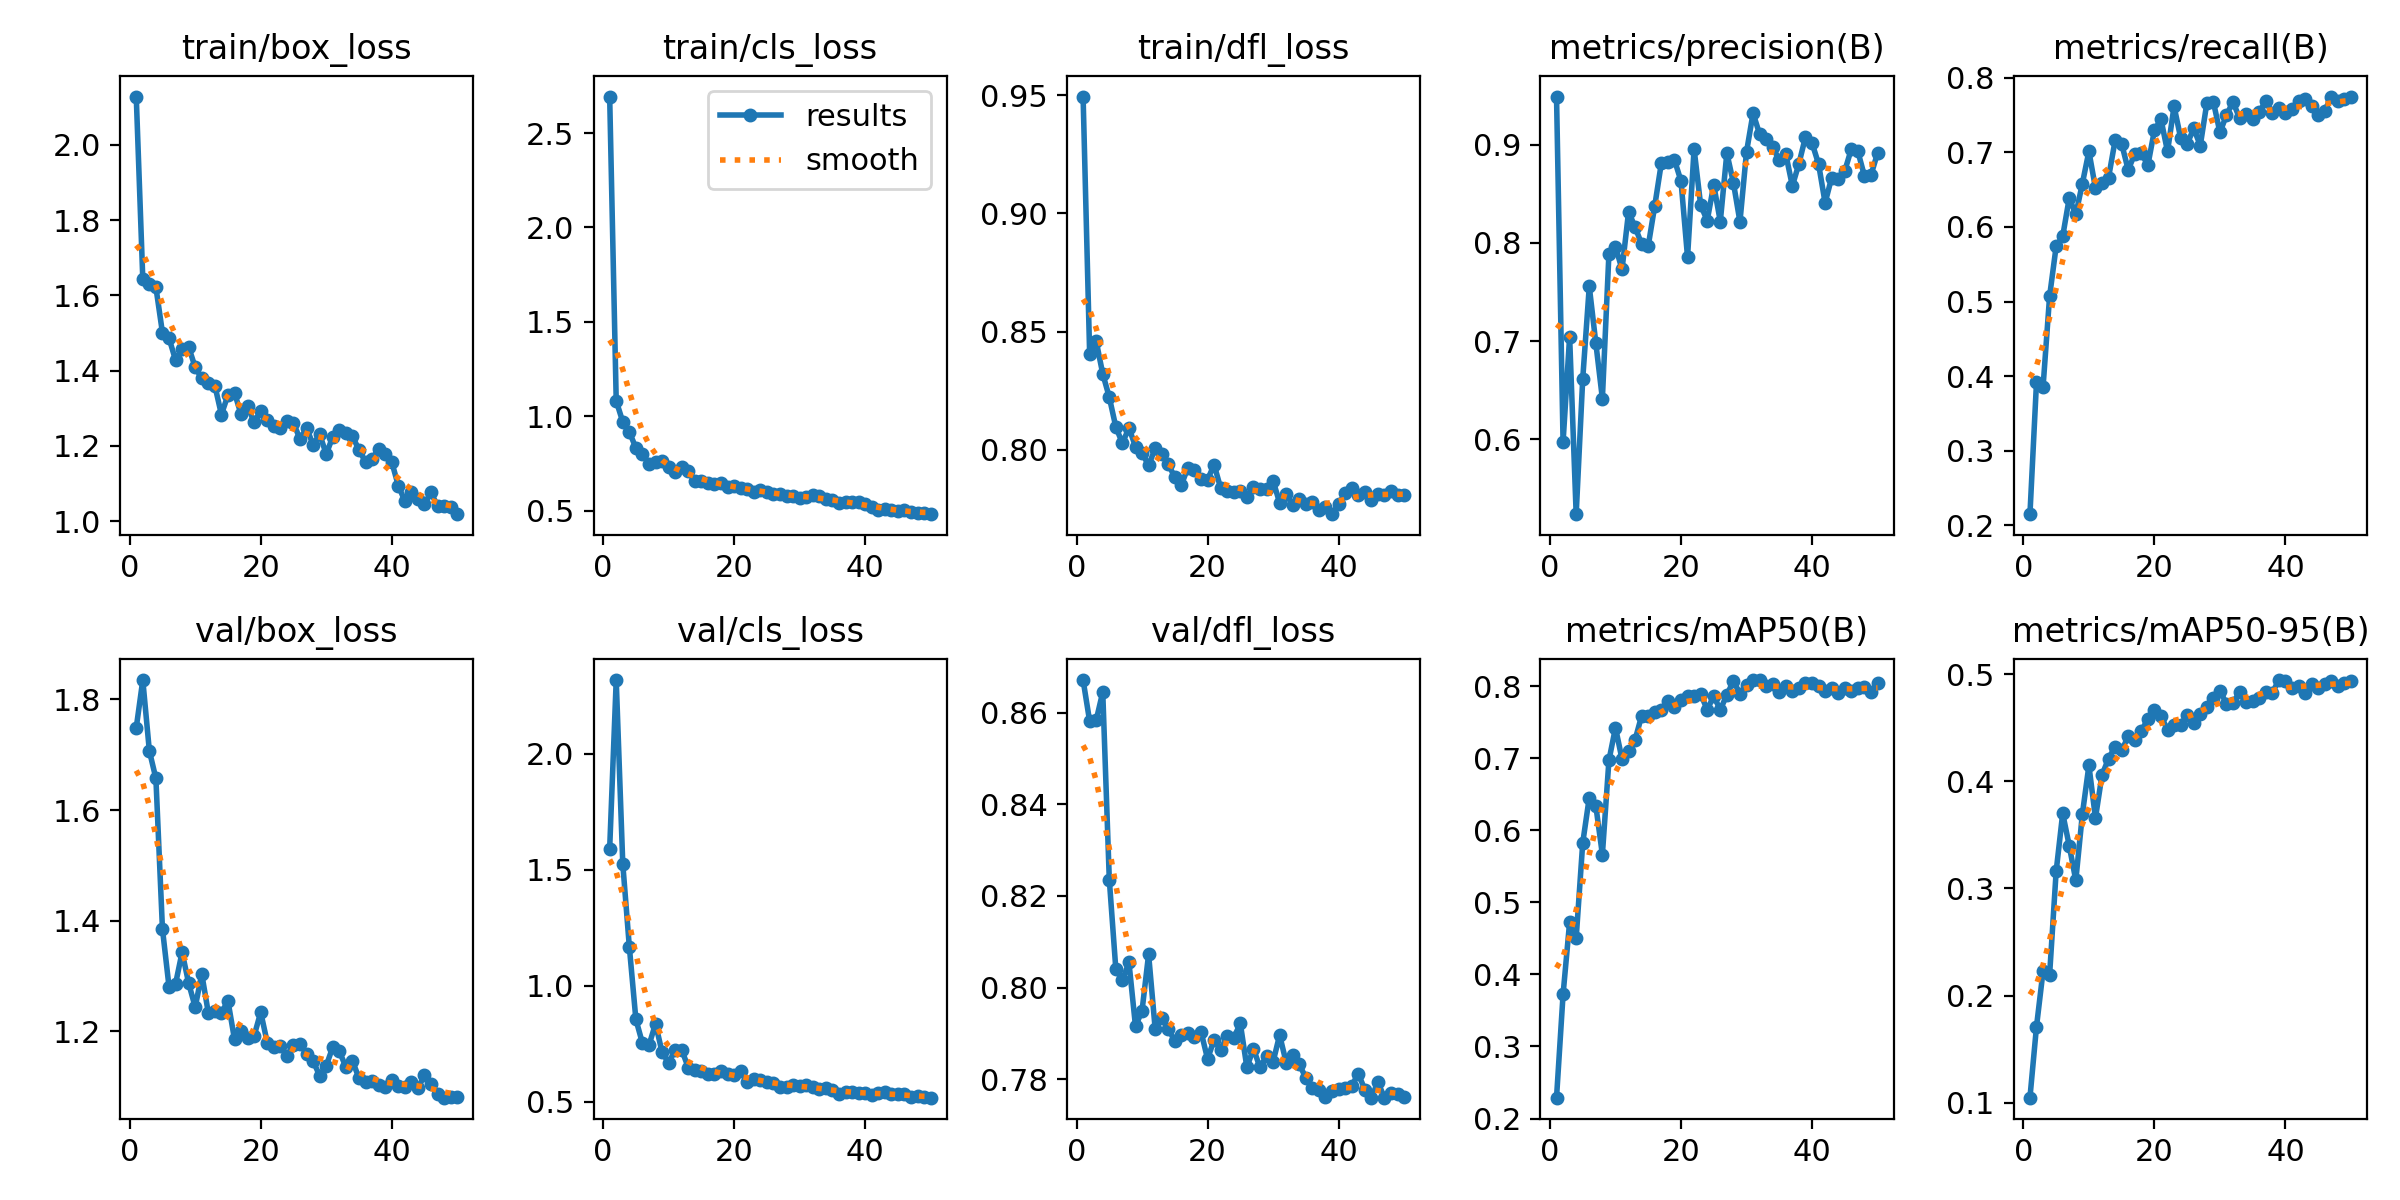

In [9]:
from IPython.display import Image
Image("/content/drive/MyDrive/football/run1/results.png")

In [10]:
model = YOLO("/content/drive/MyDrive/football/run1/weights/best.pt")
metrics = model.val()
print(model.names)       # the class names you must match in role_map
print(metrics.box.map50) # overall mAP50

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1286.6±419.9 MB/s, size: 52.9 KB)
val: Scanning /content/football-players-detection-20/valid/labels.cache... 49 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 11.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.2s/it 4.7s
                   all         49       1174       0.89      0.767      0.803      0.498
                  ball         45         45       0.79      0.333      0.352      0.119
            goalkeeper         38         39       0.92       0.89      0.944      0.612
                player         49        973       0.95      0.973      0.983      0.687
               referee         49        117      0.901      0.872      0.933      0.574
Speed: 13.9ms preprocess, 24.

In [11]:
model.predict(source="/content/video.mp4", conf=0.3, save=True)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/750) /content/video.mp4: 384x640 1 ball, 21 players, 4 referees, 24.3ms
video 1/1 (frame 2/750) /content/video.mp4: 384x640 1 ball, 21 players, 4 referees, 27.3ms
video 1/1 (frame 3/750) /content/video.mp4: 384x640 21 players, 3 referees, 23.2ms
video 1/1 (frame 4/750) /content/video.mp4: 384x640 1 ball, 23 players, 3 referees, 38.0ms
video 1/1 (frame 5/750) /content/video.mp4: 384x640 1 ball, 26 players, 3 referees, 26.8ms
video 1/1 (f

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'ball', 1: 'goalkeeper', 2: 'player', 3: 'referee'}
 obb: None
 orig_img: array([[[100, 146, 105],
         [ 92, 138,  97],
         [ 97, 150, 101],
         ...,
         [100,  92,  82],
         [103,  95,  85],
         [105,  97,  87]],
 
        [[ 99, 145, 104],
         [ 99, 145, 104],
         [109, 162, 113],
         ...,
         [105,  97,  87],
         [107,  99,  89],
         [108, 100,  90]],
 
        [[ 96, 149, 100],
         [105, 158, 109],
         [112, 170, 113],
         ...,
         [106,  98,  88],
         [108, 100,  90],
         [110, 102,  92]],
 
        ...,
 
        [[ 74, 103,  78],
         [ 74, 103,  78],
         [ 74, 103,  78],
         ...,
         [ 30,  47,  43],
         [ 31,  48,  44],
         [ 31,  48,  44]],
 
        [[ 74, 103,  78],
         [ 74, 103,  78],
   

In [12]:
from google.colab import files
files.download("/content/drive/MyDrive/football/run1/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>